# LoRA: эффективное дообучение трансформеров

Ключевая причина, почему для CNN transfer learning дешевый, а для трансформеров нет заключается в разнице числа параметров и в том, как они распределены по модели.

У классической CNN (ResNet50, EfficientNet) большая часть параметров сосредоточена в сверточных фильтрах, а сама сеть по современным меркам небольшая, десятки миллионов параметров. Дообучить ее целиком, даже под маленький датасет, не так рискованно: параметров умеренно и обучение быстро сходится.

Трансформеры устроены иначе: даже "маленький" ViT-Base это уже 86M+ параметров, а языковые модели легко переваливают за миллиарды. Полное дообучение такой модели это не только дорого по памяти, но и рискованно по качеству: если датасет маленький, то обновление всех 86M параметров может легко переобучиться или "забыть" полезные предобученные признаки.

Возникает вопрос: можно ли дообучить трансформер, обновляя не все веса, а маленькую их часть, и почти не теряя в качестве? Один из самых популярных ответов на этот вопрос **LoRA (Low-Rank Adaptation)**.

## Идея LoRA

Идея LoRA в том, что изменения больших весовых матриц при дообучении почти всегда **низкоранговые** это эмпирическое наблюдение [[paper] 📄 Aghajanyan et al., 2020, Intrinsic Dimensionality](https://arxiv.org/abs/2012.13255), на которое опирается сама статья LoRA [[paper] 📄 Hu et al., 2021, LoRA: Low-Rank Adaptation of Large Language Models](https://arxiv.org/abs/2106.09685): чтобы адаптировать предобученную модель под новую задачу, реальная поправка $\Delta W$ к любой весовой матрице $W$ хорошо приближается матрицей низкого ранга, даже если сама $W$ полноранговая. Поэтому $\Delta W$ выгодно не хранить и учить как одну огромную матрицу, а представить как произведение двух маленьких, что радикально уменьшает число обучаемых параметров и память, при почти том же эффекте, что и полный fine-tuning.


<center><img src ="https://ml.gan4x4.ru/wb/cv/images/lora_a_b.png"  width="500"></center>

<center><em> Source: <a href="https://arxiv.org/abs/2106.09685">LoRA</a></em></center>

Для линейного слоя с весом $W_0 \in \mathbb{R}^{d \times k}$ поправка представляется как:

$$ \Delta W = B A, \quad B \in \mathbb{R}^{d \times r}, \quad A \in \mathbb{R}^{r \times k}, \quad r \ll \min(d, k) $$

Итоговый forward pass слоя:

$$ h = W_0 x + \Delta W x = W_0 x + B A x $$

Чтобы объявить обучаемую матрицу низкого ранга, недостаточно просто взять $\Delta W$ той же формы $d \times k$, что и $W_0$, и учить её — это была бы обычная поправка полного ранга, а по числу параметров ничем не отличалось бы от full fine-tuning этого слоя. Низкий ранг нужно получить из самой конструкции: произведение матрицы $d \times r$ на матрицу $r \times k$ **гарантированно** имеет ранг не больше $r$ при любых значениях $B$ и $A$ это свойство линейной алгебры, а не отдельное ограничение, которое надо накладывать при оптимизации. Поэтому $B$ и $A$ обучаются обычным градиентным спуском без всяких ограничений, а низкий ранг получается сам собой из формы произведения. И заодно число обучаемых параметров падает с $d \times k$ до $r(d+k)$ при $r \ll \min(d,k)$ это на порядки меньше.

$W_0$ (исходные предобученные веса) **замораживаются полностью** и не получают градиент. Обучаются только $A$ и $B$ это и есть LoRA-адаптер.

Инициализация матриц выбрана несимметрично:
* $A$ — случайные числа (обычно из нормального распределения)
* $B$ — нулями

Почему так:

* При $B=0$ произведение $BA=0$ вне зависимости от значений в $A$, а значит, в начале обучения $\Delta W = 0$, и модель ведет себя ровно как предобученная, без случайного шума от новых слоев на первом же шаге.
* Если бы обе матрицы были нулевыми, обучение вообще не сдвинулось бы с места. Несимметричная инициализация разрывает эту зависимость: $A$ ненулевая и случайная, поэтому градиент по $B$ (пропорциональный $A$) на первом же шаге не нулевой и $B$ начинает сдвигаться от нуля. А как только $B$ становится ненулевой, градиент по $A$ (пропорциональный $B$) тоже становится ненулевым, и $A$ включается в обучение следом.

Есть ещё один гиперпараметр $\alpha$ (`lora_alpha`), масштабирующий вклад адаптера:

$$ h = W_0 x + \frac{\alpha}{r} B A x $$

Он позволяет менять "силу" адаптации, не трогая learning rate, на практике часто держат $\alpha = 2r$ или $\alpha = r$ и подбирают эмпирически.

## Сколько параметров реально экономит LoRA

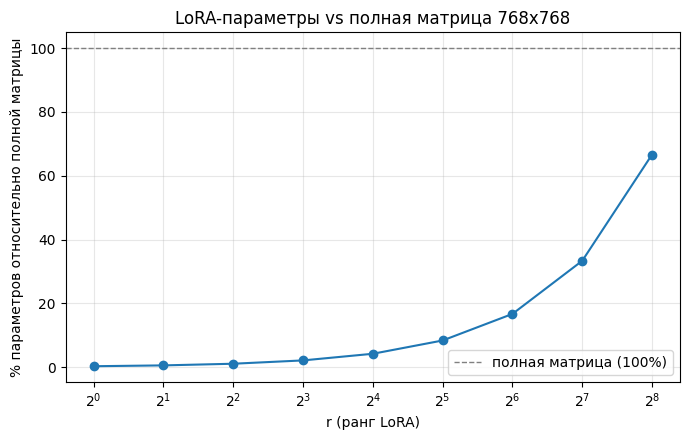

r=1    параметров адаптера:   1,536 (0.26% от 589,824)
r=2    параметров адаптера:   3,072 (0.52% от 589,824)
r=4    параметров адаптера:   6,144 (1.04% от 589,824)
r=8    параметров адаптера:  12,288 (2.08% от 589,824)
r=16   параметров адаптера:  24,576 (4.17% от 589,824)
r=32   параметров адаптера:  49,152 (8.33% от 589,824)
r=64   параметров адаптера:  98,304 (16.67% от 589,824)
r=128  параметров адаптера: 196,608 (33.33% от 589,824)
r=256  параметров адаптера: 393,216 (66.67% от 589,824)


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

d, k = 768, 768  # типичная размерность проекции внимания в ViT-Base / BERT-Base

full_params = d * k
ranks = [1, 2, 4, 8, 16, 32, 64, 128, 256]
lora_params = [r * (d + k) for r in ranks]
pct = [100 * p / full_params for p in lora_params]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(ranks, pct, marker="o")
ax.axhline(100, color="gray", linestyle="--", linewidth=1, label="полная матрица (100%)")
ax.set_xlabel("r (ранг LoRA)")
ax.set_ylabel("% параметров относительно полной матрицы")
ax.set_title(f"LoRA-параметры vs полная матрица {d}x{k}")
ax.set_xscale("log", base=2)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

for r, p, pc in zip(ranks, lora_params, pct):
    print(f"r={r:<4} параметров адаптера: {p:>7,} ({pc:.2f}% от {full_params:,})")

Даже при $r=64$ (довольно большой ранг для практики) адаптер одной проекции это меньше 17% от размера полной матрицы, а типичные значения $r=4$–$16$ это доли процента. Причём это на **одну** проекцию, а LoRA обычно ставят на несколько проекций (`query`, `value`, иногда `key` и `output`) в каждом слое внимания, и итоговый процент от **всей** модели (со всеми MLP-слоями, эмбеддингами и т.д.) получается еще меньше.

## Куда встраивать адаптеры

LoRA можно поставить на любой линейный слой, но не все слои одинаково полезны для адаптации:

* **Attention-проекции** (`query`, `key`, `value`, `output`) самое частое место. В оригинальной статье LoRA лучший компромисс качество/параметры давала адаптация именно `query` и `value`.
* **MLP-слои** (`fc1`/`fc2`, `up_proj`/`down_proj`/`gate_proj` в трансформерах для LLM) тоже часто адаптируют, особенно если задача требует более существенных изменений поведения модели.
* **Классификационная голова** обычно не заворачивается в low-rank форму, а просто дообучается целиком, потому что она новая и маленькая, разложение ее в LoRA не дает экономии.

В результате экспериментов авторы статьи пришли к заключению, что `query`+`value` дает лучший компромисс между качеством и числом обучаемых параметров.


# LoRA на практике: библиотека PEFT

Теоретически LoRA не требует специальных библиотек, ее можно реализовать самостоятельно. Для этого достаточно заменить нужные ``nn.Linear`` на слой, который хранит замороженный исходный вес и две небольшие обучаемые low-rank матрицы. Однако вручную модифицировать каждую архитектуру (BERT, ViT, LLaMA и др.), искать подходящие слои и поддерживать такой код неудобно и легко ошибиться.


[[doc] 🛠️ PEFT (Parameter-Efficient Fine-Tuning)](https://github.com/huggingface/peft) это библиотека от Hugging Face, которая делает это за нас поверх любой модели `transformers`. Основной цикл работы:

1. Загрузить предобученную модель как обычно.
2. Описать `LoraConfig`, куда встраивать адаптеры и с какими параметрами.
3. Обернуть модель `get_peft_model(model, config)` и PEFT сам заменит нужные `nn.Linear` на версии с добавленным low-rank адаптером и заморозит все остальное.
4. Обучать как обычную модель. Оптимизатор увидит градиенты только у LoRA-параметров.


In [ ]:
!pip -q install "transformers==4.46.3" peft accelerate torchvision
!pip -q uninstall -y torchao


In [ ]:
from peft import LoraConfig, get_peft_model
from transformers import ViTForImageClassification

MODEL_ID = "google/vit-base-patch16-224-in21k"
base_model = ViTForImageClassification.from_pretrained(MODEL_ID, num_labels=10)

lora_config = LoraConfig(
    r=8,                                  # ранг адаптера
    lora_alpha=16,                        # масштабирующий коэффициент (обычно 1x-2x от r)
    target_modules=["query", "value"],    # куда встраиваем адаптеры (подстрока в имени модуля)
    lora_dropout=0.1,                     # dropout внутри адаптера, регуляризация
    bias="none",                          # bias-параметры не обучаем отдельно
    modules_to_save=["classifier"],       # классификационная часть обучается целиком
)

lora_model = get_peft_model(base_model, lora_config)
lora_model.print_trainable_parameters()

Далее можно запускать обучение, примерный шаблон выглядит так:

```python
from transformers import TrainingArguments, Trainer

training_args = TrainingArguments(
    output_dir="./lora_demo",
    per_device_train_batch_size=32,
    num_train_epochs=3,
    learning_rate=5e-4,
    label_names=["labels"],
)

trainer = Trainer(
    model=lora_model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
)

trainer.train()

```

## Слияние адаптера обратно в веса

После обучения LoRA-адаптер можно оставить отдельно (тогда на каждый forward нужно дополнительное умножение $BAx$), а можно **слить** его обратно в исходные веса:

$$ W_{merged} = W_0 + \frac{\alpha}{r} B A $$

После слияния модель по архитектуре и по скорости инференса неотличима от обычной дообученной модели. В PEFT это делается одним вызовом:

In [ ]:
from peft import PeftModel

print("До слияния:", type(lora_model))
merged_model = lora_model.merge_and_unload()
print("После слияния:", type(merged_model))

print("Это PeftModel?", isinstance(merged_model, PeftModel))

Если слияние не делать, а сохранить адаптер отдельно (`lora_model.save_pretrained("adapter_task_a")`), на диске окажутся только матрицы $A$ и $B$ обычно единицы-десятки мегабайт, вместо гигабайтов на полную модель.

Практическая схема, которая из этого следует: **одна большая базовая модель держится в памяти один раз**, а под разные задачи подключаются разные маленькие адаптеры без выгрузки и повторной загрузки базовых весов.



Системы вроде [[paper] 📄 S-LoRA: Serving Thousands of Concurrent LoRA Adapters](https://arxiv.org/abs/2311.03285) идут еще дальше и умеют обслуживать **батч запросов с разными адаптерами одновременно**, а не только переключаться последовательно то есть сотни клиентов с разными задачами могут делить одну и ту же базовую модель на одном GPU.

Из этой же дешевизны адаптеров следует ещё один практический приём это **ансамбль на адаптерах**, можно обучить несколько разных LoRA поверх одной и той же замороженной базы (разные seed, разные подвыборки данных, разные ранги) и на инференсе усреднять их предсказания.

# Вариации LoRA

LoRA не единственный вариант low-rank адаптации, вокруг неё выросло целое семейство модификаций под разные практические нужды.

## QLoRA

[[paper] 📄 Dettmers et al., 2023, QLoRA: Efficient Finetuning of Quantized LLMs](https://arxiv.org/abs/2305.14314)

Базовая модель хранится в квантованном виде (обычно 4-бит), а LoRA-адаптеры поверх нее обучаются в обычной точности (bf16/fp32). Это резко снижает требования к памяти именно для хранения весов базовой модели и позволяет дообучать модели, которые в полной точности физически не помещаются на доступную GPU.

## LoRA+

[[paper] 📄 Hayou et al., 2024, LoRA+: Efficient Low Rank Adaptation of Large Models](https://arxiv.org/abs/2402.12354)

В исходной LoRA матрицы $A$ и $B$ обучаются с одним и тем же learning rate, хотя по анализу градиентов оптимальные скорости обучения для них разные ($B$ обычно нужно обучать быстрее). LoRA+ вводит отдельный (обычно больший) learning rate для $B$, что ускоряет сходимость почти без дополнительных затрат.

## DoRA (Weight-Decomposed LoRA)

[[paper] 📄 Liu et al., 2024, DoRA: Weight-Decomposed Low-Rank Adaptation](https://arxiv.org/abs/2402.09353)

Идея: любую матрицу весов можно разложить на **величину** (magnitude) и **направление** (direction):

$$ W_0 = m \cdot \frac{V}{\lVert V \rVert_c}, \qquad m \in \mathbb{R}^{1 \times k}, \quad V \in \mathbb{R}^{d \times k} $$

где $\lVert V \rVert_c$ — норма по столбцам, а $m$ — вектор длин (по одному числу на выходной нейрон). Обычная LoRA добавляет $\Delta W = BA$ сразу к $W_0$ целиком, поэтому в одном обновлении неявно меняются и величина, и направление весов, причем связанным образом. DoRA явно разделяет обновление:

$$ W' = m' \cdot \frac{V + BA}{\lVert V + BA \rVert_c} $$

Направление ($V$) адаптируется через low-rank LoRA-поправку, как обычно, а величина ($m'$) обучается **отдельно и напрямую**, без low-rank ограничения это дешево, потому что $m$ это вектор размера $k$, а не матрица. По наблюдениям авторов, при полном дообучении величина и направление весов меняются характерным образом, который обычная LoRA плохо воспроизводит, а разделение на два независимых пути обучения ближе к этому паттерну и эмпирически дает качество ближе к full fine-tuning при том же числе параметров, что и у обычной LoRA.

In [ ]:
import torch

# Иллюстрация самого разложения на величину и направление
W = torch.randn(10, 6)  # случайная матрица весов: 10 выходных нейронов, 6 входных

magnitude = W.norm(dim=1, keepdim=True)     # m: по одному числу на выходной нейрон, размерность (10, 1)
direction = W / magnitude                    # V: размерность как W, но каждая строка единичной длины

print("Размерность magnitude:", magnitude.shape)
print("Размерность direction:", direction.shape)
print("Норма строк direction (должна быть ~1):", direction.norm(dim=1)[:5])

Форма magnitude: torch.Size([10, 1])
Форма direction: torch.Size([10, 6])
Норма строк direction (должна быть ~1): tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000])


В библиотеке PEFT DoRA уже встроена, достаточно указать `LoraConfig(..., use_dora=True)`.

## AdaLoRA

[[paper] 📄 Zhang et al., 2023, AdaLoRA: Adaptive Budget Allocation for Parameter-Efficient Fine-Tuning](https://arxiv.org/abs/2303.10512)

В обычной LoRA ранг $r$ фиксирован и одинаков для всех адаптируемых слоев. AdaLoRA обучается с избыточным начальным бюджетом рангов и постепенно **обрезает** менее важные компоненты по ходу обучения (оценивая важность через что-то вроде сингулярных значений), перераспределяя оставшийся бюджет параметров на те слои, которым он нужнее.

## LoHa / LoKr

Используются в первую очередь в сообществе дообучения диффузионных моделей (Stable Diffusion) наравне с LoRA, часто под общим названием библиотек вроде [[doc] 🛠️ LyCORIS](https://github.com/KohakuBlueleaf/LyCORIS):

* **LoHa** (Low-Rank Hadamard Product) — комбинирует две low-rank декомпозиции через поэлементное произведение (произведение Адамара), что при том же числе параметров может выразить поправку более высокого эффективного ранга, чем обычная LoRA.
* **LoKr** (Low-Rank Kronecker Product) — использует произведение Кронекера вместо обычного матричного произведения, что особенно эффективно для очень больших матриц весов.

## T-LoRA

[[paper] 📄 T-LoRA: Single Image Diffusion Model Customization Without Overfitting](https://arxiv.org/abs/2507.05964)

В отличие от предыдущих вариаций, T-LoRA заточена под очень конкретный сценарий: персонализация диффузионной модели генерации изображений (например, Stable Diffusion) **по одной-единственной картинке**. У диффузионных моделей есть понятие timestep (шаг шумоподавления), авторы заметили, что на поздних timesteps (грубые, крупные черты изображения) модель переобучается на единственный пример сильнее, чем на ранних (мелкие детали). T-LoRA динамически меняет эффективный ранг адаптера в зависимости от timestep (меньше ранга на "переобучаемых" шагах, больше на остальных) плюс использует ортогональную инициализацию матриц, чтобы разные компоненты адаптера не дублировали друг друга.

Вне задач диффузионной генерации и персонализации по единичным изображениям эта вариация вряд ли пригодится в отличие от QLoRA/DoRA/AdaLoRA, которые применимы к любому трансформеру.

# Как выбирать гиперпараметры на практике

Короткий практический чеклист, с чего начинать:

* **`target_modules`**: начать с `query`+`value` в attention это минимальный, проверенный оригинальной статьей вариант. Если качества не хватает то добавить `key`/`output`, а затем MLP-проекции.
* **`r`**: начать с небольшого значения (4-16). Увеличение ранга с какого-то момента дает все меньше прироста качества (diminishing returns), а параметров и памяти требует больше.
* **`lora_alpha`**: часто выбирают $\alpha = r$ или $\alpha = 2r$ как отправную точку, дальше подбирают вместе с learning rate.
* **`lora_dropout`**: 0.05-0.1 как разумный дефолт, особенно если train-выборка маленькая.
* **learning rate**: для LoRA обычно можно и нужно брать больше, чем для full fine-tuning того же слоя (типичный порядок — 1e-4-1e-3, против 1e-5-5e-5 для full fine-tune) потому что обучаемых параметров меньше и они инициализированы так, что стартуют с нулевого вклада.
* **`modules_to_save`**: не забыть перечислить голову классификации (или любые другие новые, не предобученные слои) иначе они останутся замороженными случайными весами.

# Итоги

LoRA решает конкретную практическую проблему: у трансформера параметров на порядки больше, чем у сопоставимой по задаче CNN, поэтому полное дообучение дорого по памяти и рискованно по качеству на небольших датасетах. Параметр-эффективная адаптация через низкоранговые поправки к весам внимания дает качество, близкое к full fine-tuning, при обучении долей процента параметров.

Вокруг базовой идеи выросло целое семейство модификаций: QLoRA для экономии памяти на самой базовой модели, LoRA+/DoRA/AdaLoRA для улучшения качества адаптации, LoHa/LoKr/T-LoRA альтернативные разложения под конкретные (в основном диффузионные) сценарии


### Ссылки для самостоятельного изучения

* [[paper] 📄 Hu et al., 2021, LoRA: Low-Rank Adaptation of Large Language Models](https://arxiv.org/abs/2106.09685)
* [[paper] 📄 Dettmers et al., 2023, QLoRA: Efficient Finetuning of Quantized LLMs](https://arxiv.org/abs/2305.14314)
* [[paper] 📄 Liu et al., 2024, DoRA: Weight-Decomposed Low-Rank Adaptation](https://arxiv.org/abs/2402.09353)
* [[paper] 📄 Zhang et al., 2023, AdaLoRA: Adaptive Budget Allocation for Parameter-Efficient Fine-Tuning](https://arxiv.org/abs/2303.10512)
* [[paper] 📄 T-LoRA: Single Image Diffusion Model Customization Without Overfitting](https://arxiv.org/abs/2507.05964)
* [[doc] 🛠️ Документация библиотеки PEFT](https://huggingface.co/docs/peft/index)
* [[doc] 🛠️ LyCORIS (LoHa/LoKr и другие варианты для диффузионных моделей)](https://github.com/KohakuBlueleaf/LyCORIS)